# ML Workflow

  Dataset
    →
  Understand columns
    →
  Clean data
    →
  Handle missing values
    →
  EDA
    →
  Identify target column
    →
  Separate X and y
    →
  Encode categorical columns
    →
  Train/Test Split
    →
  Feature Scaling (if required)
    →
  Train ML model
    →
  Prediction
    →
  Evaluate model

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [19]:
df = pd.read_table("/content/car_evaluation.csv",sep=",",header=None)

In [20]:
df = df.rename(columns={0:'buying price',1:'maintenance cost',2:'number of doors',3:'number of persons',4:'lug_boot',5:'safety',6:'decision'})

In [21]:
df.head(5)

,buying price,maintenance cost,number of doors,number of persons,lug_boot,safety,decision
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   buying price       1728 non-null   object
 1   maintenance cost   1728 non-null   object
 2   number of doors    1728 non-null   object
 3   number of persons  1728 non-null   object
 4   lug_boot           1728 non-null   object
 5   safety             1728 non-null   object
 6   decision           1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [25]:
df['decision'].value_counts()

,count
decision,
unacc,1210
acc,384
good,69
vgood,65


In [26]:
x_col = ['buying price','maintenance cost','number of doors','number of persons','lug_boot','safety']
y_col = ['decision']

In [29]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import LabelEncoder

oe = OrdinalEncoder()
le = LabelEncoder()

df[x_col] = oe.fit_transform(df[x_col])

# Use y_col[0] ('decision') as a string to match the 1D output of LabelEncoder
df[y_col[0]] = le.fit_transform(df[y_col[0]])

In [30]:
df.head(5)

,buying price,maintenance cost,number of doors,number of persons,lug_boot,safety,decision
0,3.0,3.0,0.0,0.0,2.0,1.0,2
1,3.0,3.0,0.0,0.0,2.0,2.0,2
2,3.0,3.0,0.0,0.0,2.0,0.0,2
3,3.0,3.0,0.0,0.0,1.0,1.0,2
4,3.0,3.0,0.0,0.0,1.0,2.0,2


In [31]:
df.describe()

,buying price,maintenance cost,number of doors,number of persons,lug_boot,safety,decision
count,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000
mean,1.500000,1.500000,1.500000,1.000000,1.000000,1.000000,1.553241
std,1.118358,1.118358,1.118358,0.816733,0.816733,0.816733,0.875948
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.750000,0.750000,0.750000,0.000000,0.000000,0.000000,1.000000
50%,1.500000,1.500000,1.500000,1.000000,1.000000,1.000000,2.000000
75%,2.250000,2.250000,2.250000,2.000000,2.000000,2.000000,2.000000
max,3.000000,3.000000,3.000000,2.000000,2.000000,2.000000,3.000000


<Axes: xlabel='decision', ylabel='Density'>

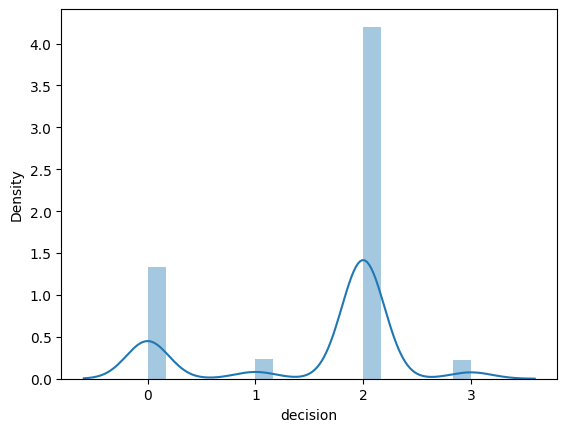

In [32]:
sns.distplot(df['decision'])

In [34]:
%pip install -q outlier-tool-shashikant

In [37]:
from outlier_tool import Outliers
o = Outliers(df)

In [38]:
o.find("iqr")

,column,method,lower,upper,outliers,percent
0,buying price,iqr,-1.5,4.5,0,0.0
1,maintenance cost,iqr,-1.5,4.5,0,0.0
2,number of doors,iqr,-1.5,4.5,0,0.0
3,number of persons,iqr,-3.0,5.0,0,0.0
4,lug_boot,iqr,-3.0,5.0,0,0.0
5,safety,iqr,-3.0,5.0,0,0.0
6,decision,iqr,-0.5,3.5,0,0.0


In [39]:
X = df.iloc[ : , :-1]
Y = df.iloc[ : ,-1]

In [40]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42, stratify=Y)

In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

DTC = DecisionTreeClassifier()
DTC.fit(X_train,Y_train)
y_prid = DTC.predict(X_test)

accuracy = accuracy_score(Y_test,y_prid)
print(f"Accuracy: {accuracy} \n")

cm = confusion_matrix(Y_test,y_prid)
print(f"Confusion Matrix: \n {cm} \n")

cr = classification_report(Y_test,y_prid)
print(f"Classification Report: \n {cr} \n")

train = DTC.score(X_train,Y_train)
print(f"Train Score: {train}")

test = DTC.score(X_test,Y_test)
print(f"Test Score: {test}")

Accuracy: 0.9884393063583815 

Confusion Matrix: 
 [[ 76   1   0   0]
 [  0  14   0   0]
 [  2   0 240   0]
 [  1   0   0  12]] 

Classification Report: 
               precision    recall  f1-score   support

           0       0.96      0.99      0.97        77
           1       0.93      1.00      0.97        14
           2       1.00      0.99      1.00       242
           3       1.00      0.92      0.96        13

    accuracy                           0.99       346
   macro avg       0.97      0.98      0.97       346
weighted avg       0.99      0.99      0.99       346
 

Train Score: 1.0
Test Score: 0.9884393063583815


In [48]:
import numpy as np
import pandas as pd

# Let's collect inputs for the car evaluation
new_input = {}
print("Enter values for the car features to make a prediction.\n")

# Map of features to their known valid categories from the encoder
for col_idx, col in enumerate(X.columns):
    valid_categories = list(oe.categories_[col_idx])
    val = input(f"Enter '{col}'")
    new_input[col] = [val]

new_df = pd.DataFrame(new_input)

try:
    # Encode input features using the already fitted OrdinalEncoder
    encoded_features = oe.transform(new_df)

    # Generate predictions and probabilities
    pred_numeric = DTC.predict(encoded_features)[0]
    probabilities = DTC.predict_proba(encoded_features)[0]

    # Decode prediction to original class name
    pred_label = le.inverse_transform([pred_numeric])[0]

    print(f"\nPrediction: The car evaluation decision is '{pred_label}'")
    print("Class Probabilities:")
    for class_name, prob in zip(le.classes_, probabilities):
        print(f"  - {class_name}: {round(prob * 100, 2)}%")
except Exception as e:
    print(f"\nError during prediction: {e}")
    print("Make sure the inputs matches the exact category values from the original dataset.")

Enter values for the car features to make a prediction.

Enter  buying price0
Enter  maintenance cost0
Enter  number of doors2
Enter  number of persons30
Enter  lug_boot4
Enter  safety6

Error during prediction: Found unknown categories ['0'] in column 0 during transform
Make sure the inputs matches the exact category values from the original dataset.
